# Financial Document Classification – Training & Evaluation

**Use case.** This project builds on my Introduction to Machine Learning summative (*credit card default
risk prediction*, tabular data). Before a lender can score a credit application, the documents the
applicant submits (invoices, budgets, forms, letters, resumes, ...) must be sorted. This notebook trains an
**image** classifier that recognises the document type from a scanned page.

**Dataset.** [RVL-CDIP](https://www.cs.cmu.edu/~aharley/rvl-cdip/) (Harley, Ufkes & Derpanis, *ICDAR 2015*):
400,000 scanned business documents in 16 types, used here through the Kaggle copy
[`abdellatifsassioui/rvlcdip`](https://www.kaggle.com/datasets/abdellatifsassioui/rvlcdip). We keep the 9
types a lender receives with a credit application.

**Where it runs.** On **Kaggle with a GPU** (the full dataset is mounted there and training takes minutes).
Run locally, the notebook falls back to the small RVL-CDIP small-200 subset in `data/`.

**Contents.** 1) Data acquisition · 2) Exploration · 3) Preprocessing · 4) Model creation · 5) Training ·
6) Evaluation (accuracy, precision, recall, F1, confusion matrix, report) · 7) Prediction functions ·
8) Saving & registering the model.

In [1]:
import os, sys, json, time, shutil, subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()
REPO_URL = "https://github.com/ingdia/image-classification-ml-pipeline.git"
REPO_BRANCH = "feature/image-classification-pipeline"
if ON_KAGGLE:
    # Get the project's src/ package from GitHub so training uses exactly the same code as the API
    REPO = Path("/tmp/repo")
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-b", REPO_BRANCH, REPO_URL, str(REPO)], check=True)
    os.environ["DATA_DIR"] = "/tmp/data"                      # sampled RVL-CDIP subset (not saved as output)
    os.environ["MODELS_DIR"] = "/kaggle/working/models"       # model + metrics are the notebook's output
    os.environ["RUNTIME_DIR"] = "/tmp/runtime"
    os.environ["FINE_TUNE_LAYERS"] = "60"                     # more data -> we can safely unfreeze more layers
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from src.config import CLASS_NAMES, TRAIN_DIR, VAL_DIR, TEST_DIR, SAMPLES_DIR, MODELS_DIR, DATA_DIR, IMG_SIZE
from src import preprocessing, model as M, registry
from src.dataset_stats import compute_stats

sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
print("on Kaggle:", ON_KAGGLE, "| data:", DATA_DIR, "| models:", MODELS_DIR)

Cloning into '/tmp/repo'...


TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
on Kaggle: True | data: /tmp/data | models: /kaggle/working/models


## 1. Data acquisition

* **RVL-CDIP small-200** (`scripts/download_data.py`, from Hugging Face): 200 images per type. Its 40-per-type
  test split is the set the **deployed API** evaluates on and uses in the retraining promotion gate, so we
  download it here too and also evaluate the model on it.
* **Full RVL-CDIP** (`scripts/build_rvl_subset.py`, Kaggle input): from each *official* split we sample
  **2,000 train / 250 validation / 250 test** images per type with a fixed seed, and convert the TIFF scans to
  grayscale PNG. Every image that also appears in small-200 is excluded, so the API's test set stays unseen.

In [2]:
SMALL200 = Path("/tmp/small200")
if ON_KAGGLE:
    t0 = time.time()
    # 1) small-200 (Hugging Face) -> /tmp/small200/{train,val,test,samples}
    subprocess.run([sys.executable, "scripts/download_data.py"], check=True,
                   env={**os.environ, "DATA_DIR": str(SMALL200)})
    # 2) full RVL-CDIP sample -> /tmp/data/{train,val,test}
    # the dataset is mounted under /kaggle/input/<...>/rvlcdip; avoid walking its 400k image files
    rvl_root = next(p.parent.parent for pattern in ("*/labels/train.txt", "*/*/labels/train.txt", "*/*/*/labels/train.txt")
                    for p in Path("/kaggle/input").glob(pattern))
    subprocess.run([sys.executable, "scripts/build_rvl_subset.py", "--rvl-root", str(rvl_root),
                    "--out", str(DATA_DIR), "--train", "2000", "--val", "250", "--test", "250",
                    "--exclude-dir", str(SMALL200 / "raw"), "--workers", str(os.cpu_count())], check=True)
    shutil.copytree(REPO / "data" / "samples", SAMPLES_DIR, dirs_exist_ok=True)
    print(f"data acquisition: {time.time() - t0:.0f}s")
    APP_TEST_DIR = SMALL200 / "test"
else:
    APP_TEST_DIR = TEST_DIR

stats = compute_stats()
dist = stats["distribution"]
for split in ("train", "val", "test"):
    print(f"{split:5s}", sum(dist[split].values()), dist[split])

Fetching 1800 files:  56%|█████▌    | 1009/1800 [00:12<00:09, 80.47it/s]HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/vaclavpechtor/rvl_cdip-small-200/dfecd585c9b5c8fe56e8d7809d5b3cf710668dff/train%2Fmemo%2F1000039759.tif?%2Fdatasets%2Fvaclavpechtor%2Frvl_cdip-small-200%2Fresolve%2Fdfecd585c9b5c8fe56e8d7809d5b3cf710668dff%2Ftrain%2Fmemo%2F1000039759.tif=&etag=%2284c7c3d8d6910be2e35bc618970ff6adcfe7ba83%22
HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/vaclavpechtor/rvl_cdip-small-200/dfecd585c9b5c8fe56e8d7809d5b3cf710668dff/train%2Fmemo%2F1000018545_1000018559.tif?%2Fdatasets%2Fvaclavpechtor%2Frvl_cdip-small-200%2Fresolve%2Fdfecd585c9b5c8fe56e8d7809d5b3cf710668dff%2Ftrain%2Fmemo%2F1000018545_1000018559.tif=&etag=%22426e197fab2724d332742a88c899cf09a8df0d07%22
Rate limited. Waiting 99.0s before retry [Retry 1/5].
Rate limited. Waiting 99.0s before retry [Retry 1/5].
HTTP Error 429 thrown while re

budget         train= 128 val= 32 test= 40
email          train= 128 val= 32 test= 40
form           train= 128 val= 32 test= 40
handwritten    train= 128 val= 32 test= 40
invoice        train= 128 val= 32 test= 40
letter         train= 128 val= 32 test= 40
memo           train= 128 val= 32 test= 40
questionnaire  train= 128 val= 32 test= 40
resume         train= 128 val= 32 test= 40
Done. Images written to /tmp/small200
excluding 3603 small-200 images
converting 22500 scans with 4 workers ...
done: 22500/22500 images written to /tmp/data
data acquisition: 981s
train 18000 {'budget': 2000, 'email': 2000, 'form': 2000, 'handwritten': 2000, 'invoice': 2000, 'letter': 2000, 'memo': 2000, 'questionnaire': 2000, 'resume': 2000}
val   2250 {'budget': 250, 'email': 250, 'form': 250, 'handwritten': 250, 'invoice': 250, 'letter': 250, 'memo': 250, 'questionnaire': 250, 'resume': 250}
test  2250 {'budget': 250, 'email': 250, 'form': 250, 'handwritten': 250, 'invoice': 250, 'letter': 250, 'memo':

## 2. Data exploration
### 2.1 Example documents per class

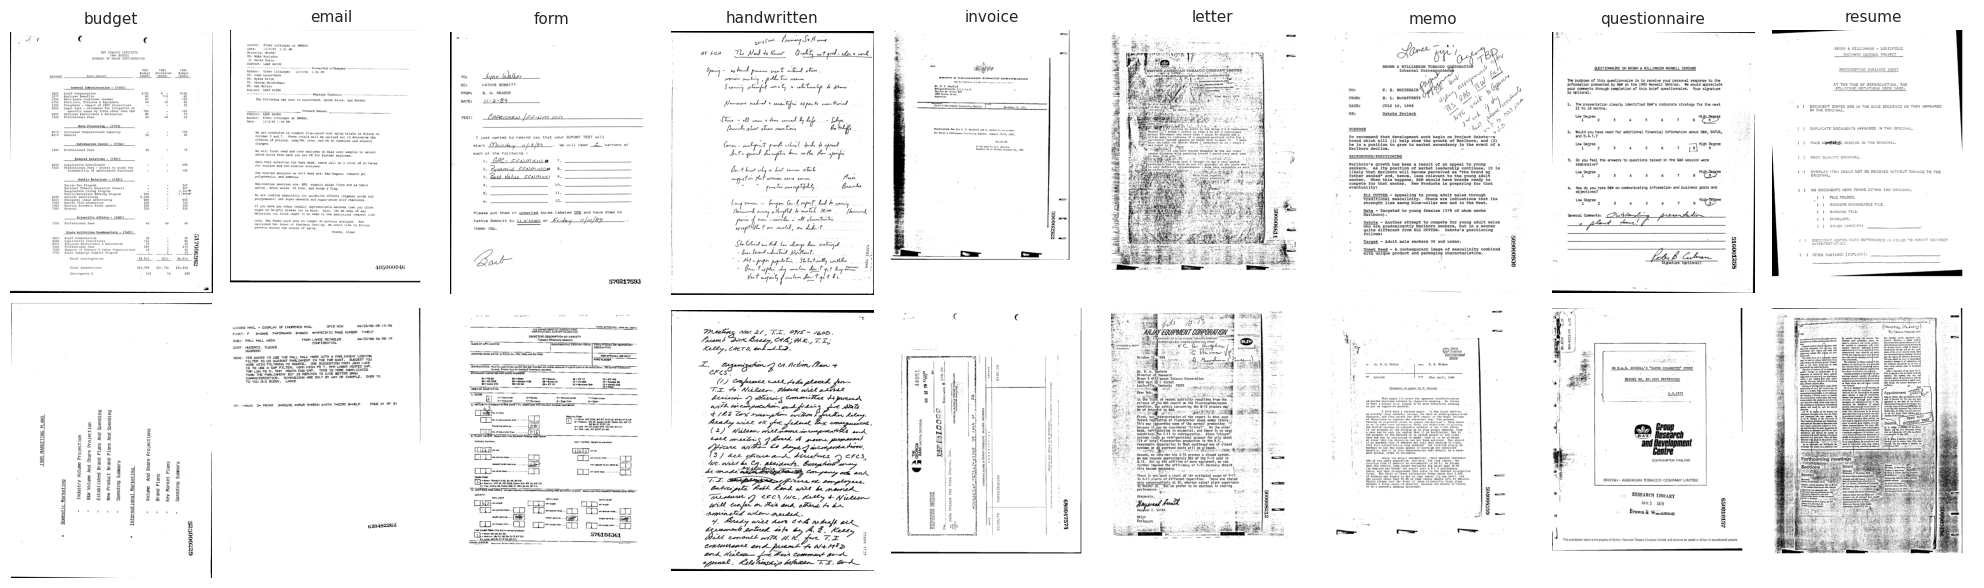

In [3]:
fig, axes = plt.subplots(2, 9, figsize=(20, 6))
for col, c in enumerate(CLASS_NAMES):
    files = sorted((TRAIN_DIR / c).glob("*.png"))[:2]
    for row, f in enumerate(files):
        axes[row, col].imshow(plt.imread(f), cmap="gray")
        axes[row, col].set_title(c if row == 0 else "", fontsize=11)
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

### 2.2 Feature 1 – class distribution

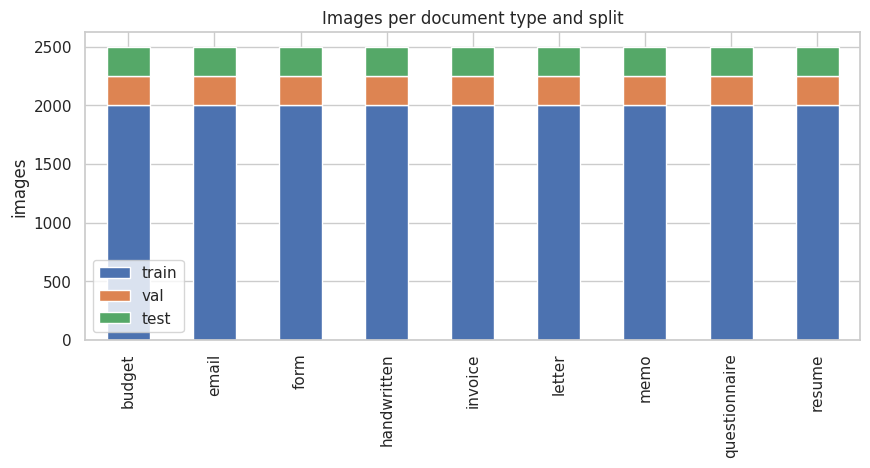

,train,val,test
budget,2000,250,250
email,2000,250,250
form,2000,250,250
handwritten,2000,250,250
invoice,2000,250,250
letter,2000,250,250
memo,2000,250,250
questionnaire,2000,250,250
resume,2000,250,250


In [4]:
import pandas as pd
df_dist = pd.DataFrame(dist)
df_dist.plot(kind="bar", stacked=True, figsize=(10, 4), title="Images per document type and split")
plt.ylabel("images"); plt.show()
df_dist

**Interpretation.** The sample is balanced by design (the same number of images per type in every split), so
accuracy is a fair headline metric and no class weighting or resampling is needed. In real lending data,
invoices and forms would dominate, which is a limitation of this setup.

### 2.3 Feature 2 – page geometry (width, height, aspect ratio)

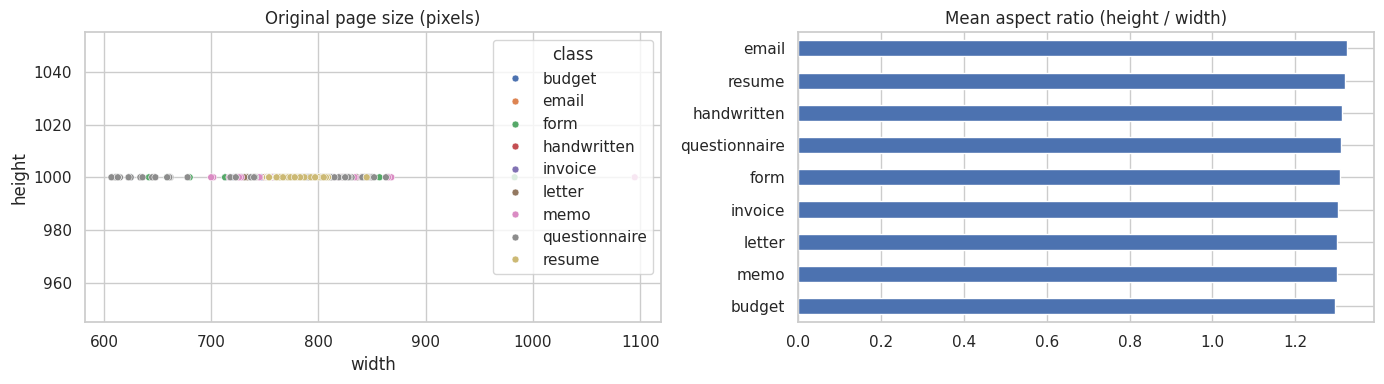

,width,height,aspect_ratio
budget,772.26,1000.0,1.30
email,755.32,1000.0,1.32
form,765.60,1000.0,1.31
handwritten,761.57,1000.0,1.31
invoice,767.05,1000.0,1.30
letter,768.98,1000.0,1.30
memo,769.47,1000.0,1.30
questionnaire,764.62,1000.0,1.31
resume,757.64,1000.0,1.32


In [5]:
sizes = pd.DataFrame(stats["sizes"])
feat = pd.DataFrame({c: {k: v["mean"] for k, v in f.items()} for c, f in stats["per_class_features"].items()}).T
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=sizes, x="width", y="height", hue="class", ax=ax[0], s=25)
ax[0].set_title("Original page size (pixels)")
feat["aspect_ratio"].sort_values().plot(kind="barh", ax=ax[1], title="Mean aspect ratio (height / width)")
plt.tight_layout(); plt.show()
feat[["width", "height", "aspect_ratio"]].round(2)

**Interpretation.** Every scan is exactly 1000 px high (RVL-CDIP was normalised this way) with widths of
roughly 750–800 px (class means 755–772 px): a portrait page with aspect ratio ≈ 1.30–1.32 for every type.
Page **shape carries almost no information about the class**, so the model has to learn from the *layout*
inside the page. Resizing to a square 224×224 slightly squashes pages, but it is the same distortion for every
class, so it does not bias the model.

### 2.4 Feature 3 – ink density and brightness

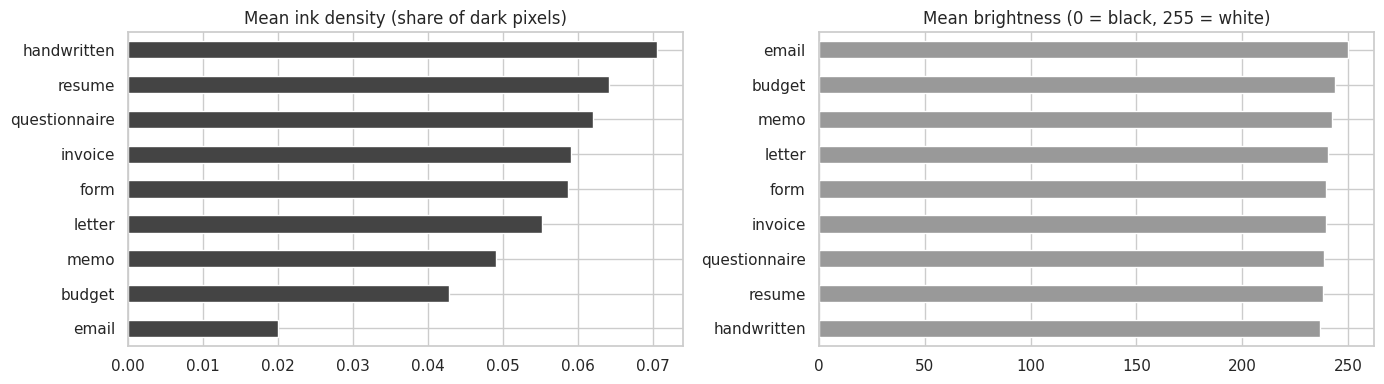

,ink_density,brightness
budget,0.043,243.785
email,0.020,249.756
form,0.059,239.761
handwritten,0.070,236.524
invoice,0.059,239.436
letter,0.055,240.631
memo,0.049,242.164
questionnaire,0.062,238.832
resume,0.064,238.312


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
feat["ink_density"].sort_values().plot(kind="barh", ax=ax[0], color="#444", title="Mean ink density (share of dark pixels)")
feat["brightness"].sort_values().plot(kind="barh", ax=ax[1], color="#999", title="Mean brightness (0 = black, 255 = white)")
plt.tight_layout(); plt.show()
feat[["ink_density", "brightness"]].round(3)

**Interpretation.** Pages are mostly white paper (mean brightness 237–250 out of 255), but the amount of ink
differs by type. Handwritten notes (7.0% dark pixels), resumes (6.4%), questionnaires (6.2%), forms and
invoices (5.9%) are the densest: handwriting strokes, ruled boxes, tables and compact sections. Emails are by
far the sparsest (2.0%): short printed messages with lots of white space, so they should be easy to recognise.
Budgets (4.3%) are sparser than expected, mostly thin columns of numbers. Letters (5.5%) and memos (4.9%) are
close in ink density and layout, so this is where we expect the most confusion. Ink density alone cannot
separate all 9 types, which is why a CNN that learns *spatial layout* is needed rather than simple statistics.

## 3. Preprocessing
Implemented in `src/preprocessing.py` and inside the model (`src/model.py`):

| Step | Where | Why |
|---|---|---|
| Decode PNG/JPEG/TIFF with Pillow | `load_image` | one loader for every format users may upload |
| Convert to grayscale, then repeat to 3 channels | `load_image` | scans are black & white; MobileNetV2 expects RGB |
| Resize to 224×224 | `load_image` | MobileNetV2's native input size |
| Label encoding (name → index) | `encode_label` | fixed class order shared by training and the API |
| Augmentation: rotation ±2%, shift ±5%, zoom ±10% (training only) | model layer | imitates crooked scans → less overfitting |
| Normalise to [-1, 1] | model layer | MobileNetV2's expected range; inside the model so prediction can never use a different scaling |

In [7]:
t0 = time.time()
x_train, y_train = preprocessing.load_dataset(TRAIN_DIR)
x_val, y_val = preprocessing.load_dataset(VAL_DIR)
x_test, y_test = preprocessing.load_dataset(TEST_DIR)
x_app, y_app = preprocessing.load_dataset(APP_TEST_DIR)   # the deployed API's test set
print(f"train {x_train.shape}, val {x_val.shape}, test {x_test.shape}, api-test {x_app.shape}  dtype={x_train.dtype}  ({time.time()-t0:.0f}s)")

train (18000, 224, 224, 3), val (2250, 224, 224, 3), test (2250, 224, 224, 3), api-test (360, 224, 224, 3)  dtype=uint8  (204s)


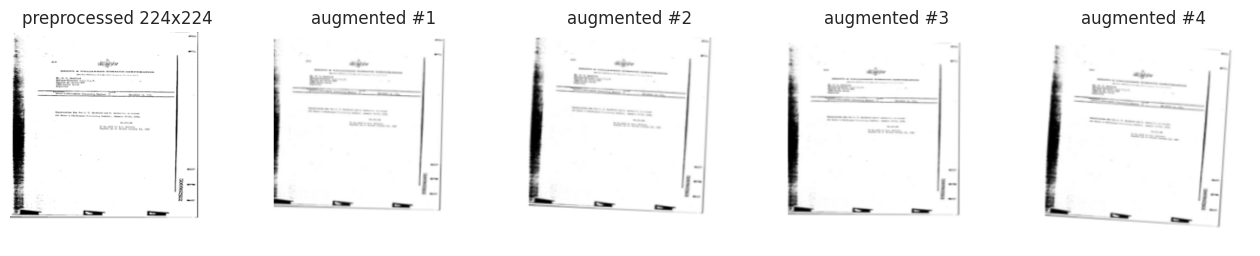

In [8]:
# Visualise preprocessing and augmentation on one invoice
sample = x_train[y_train == CLASS_NAMES.index("invoice")][0]
aug = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.02, fill_mode="constant", fill_value=255.0),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=255.0),
    tf.keras.layers.RandomZoom(0.1, fill_mode="constant", fill_value=255.0)])
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(sample); axes[0].set_title("preprocessed 224x224")
for i in range(1, 5):
    axes[i].imshow(aug(sample[None].astype("float32"), training=True)[0].numpy().astype("uint8"))
    axes[i].set_title(f"augmented #{i}")
for a in axes: a.axis("off")
plt.show()

## 4. Model creation – MobileNetV2 transfer learning
**Why MobileNetV2?** Even with 2,000 images per type, training a CNN from scratch would overfit and need
far more compute. MobileNetV2 was pretrained on 1.2M ImageNet photos and already detects edges, lines, blocks and textures.
We reuse those features and train a new 9-class head. It is small (~3.5M parameters, ~10 MB) and fast on
CPU, which matters for serving many requests in the load test.

In [9]:
model = M.build_model()
model.summary(show_trainable=True)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "doc_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ normalize (Rescaling)       │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 9)             │     11,529 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Training
**Stage 1 – feature extraction:** backbone frozen, only the classifier head is trained (Adam, lr 1e-3).
**Stage 2 – fine-tuning:** the top 60 backbone layers (30 when run locally on the small dataset) are unfrozen with lr 1e-5 so they adapt from photos to
document layouts. Early stopping on validation accuracy (patience 4) restores the best weights.

In [10]:
t0 = time.time()
EPOCHS, FINE_TUNE_EPOCHS, BATCH = (15, 15, 64) if ON_KAGGLE else (15, 8, 32)
history = M.train(model, x_train, y_train, x_val, y_val, epochs=EPOCHS, fine_tune_epochs=FINE_TUNE_EPOCHS, batch_size=BATCH)
train_seconds = time.time() - t0
print(f"training time: {train_seconds/60:.1f} min")

Epoch 1/15
282/282 - 41s - 146ms/step - accuracy: 0.4560 - loss: 1.5441 - val_accuracy: 0.4858 - val_loss: 1.4760 - learning_rate: 0.0010
Epoch 2/15
282/282 - 30s - 107ms/step - accuracy: 0.5674 - loss: 1.2660 - val_accuracy: 0.5080 - val_loss: 1.3917 - learning_rate: 0.0010
Epoch 3/15
282/282 - 32s - 112ms/step - accuracy: 0.5881 - loss: 1.1960 - val_accuracy: 0.5111 - val_loss: 1.3761 - learning_rate: 0.0010
Epoch 4/15
282/282 - 33s - 118ms/step - accuracy: 0.6019 - loss: 1.1573 - val_accuracy: 0.5324 - val_loss: 1.3182 - learning_rate: 0.0010
Epoch 5/15
282/282 - 33s - 117ms/step - accuracy: 0.6113 - loss: 1.1356 - val_accuracy: 0.5396 - val_loss: 1.3155 - learning_rate: 0.0010
Epoch 6/15
282/282 - 33s - 115ms/step - accuracy: 0.6124 - loss: 1.1252 - val_accuracy: 0.5373 - val_loss: 1.3157 - learning_rate: 0.0010
Epoch 7/15

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
282/282 - 33s - 117ms/step - accuracy: 0.6206 - loss: 1.1140 - val_accuracy: 0.5298 

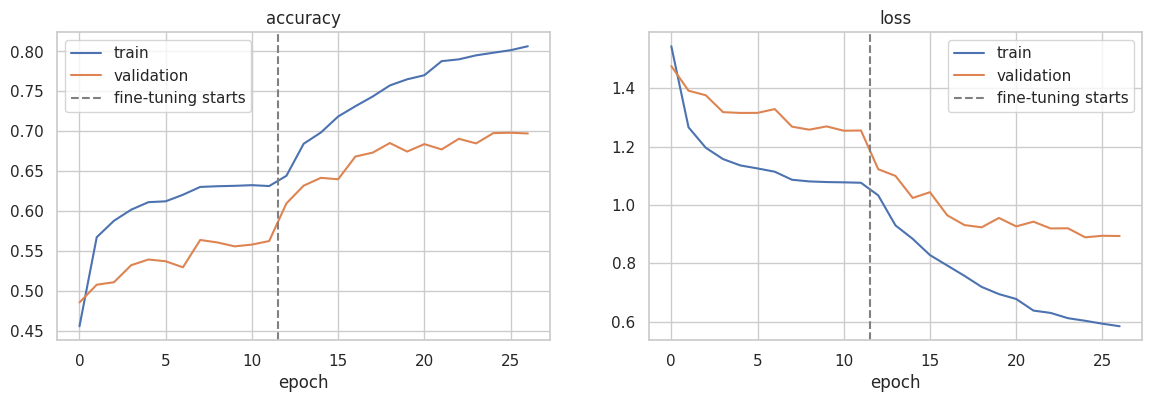

In [11]:
ft = history["fine_tune_start_epoch"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for metric, a in zip(("accuracy", "loss"), ax):
    a.plot(history[metric], label="train"); a.plot(history["val_" + metric], label="validation")
    a.axvline(ft - 0.5, ls="--", c="gray", label="fine-tuning starts")
    a.set_title(metric); a.set_xlabel("epoch"); a.legend()
plt.show()

**Reading the curves.** In stage 1 (frozen backbone) validation accuracy climbs to about 56%: the ImageNet
features are useful but were learned on photos. Once the top 60 layers are fine-tuned it rises further to
**≈70%**, so adapting the backbone to document layouts is what makes the difference. Training accuracy ends
at ≈81%, about 11 points above validation: mild overfitting, limited by augmentation, dropout and early
stopping, which restores the best weights.

## 6. Evaluation on the held-out test sets
* **6.1 RVL-CDIP test sample** – 250 unseen documents per type from the official test split (main result).
* **6.2 API test set** – the 40-per-type small-200 test set that the deployed API re-evaluates on
  (`POST /evaluate`) and that the retraining promotion gate uses. Its metrics are saved as `models/metrics.json`.

### 6.1 RVL-CDIP test sample

In [12]:
metrics = M.evaluate(model, x_test, y_test)
print(f"Accuracy          {metrics['accuracy']:.3f}")
print(f"Precision (macro) {metrics['precision_macro']:.3f}")
print(f"Recall (macro)    {metrics['recall_macro']:.3f}")
print(f"F1-score (macro)  {metrics['f1_macro']:.3f}")

Accuracy          0.716
Precision (macro) 0.742
Recall (macro)    0.716
F1-score (macro)  0.716


In [13]:
pd.DataFrame(metrics["classification_report"]).T.round(3)

,precision,recall,f1-score,support
budget,0.665,0.668,0.667,250.000
email,0.973,0.856,0.911,250.000
form,0.634,0.692,0.662,250.000
handwritten,0.618,0.972,0.756,250.000
invoice,0.738,0.700,0.719,250.000
letter,0.636,0.700,0.667,250.000
memo,0.849,0.472,0.607,250.000
questionnaire,0.606,0.664,0.634,250.000
resume,0.963,0.724,0.826,250.000
accuracy,0.716,0.716,0.716,0.716


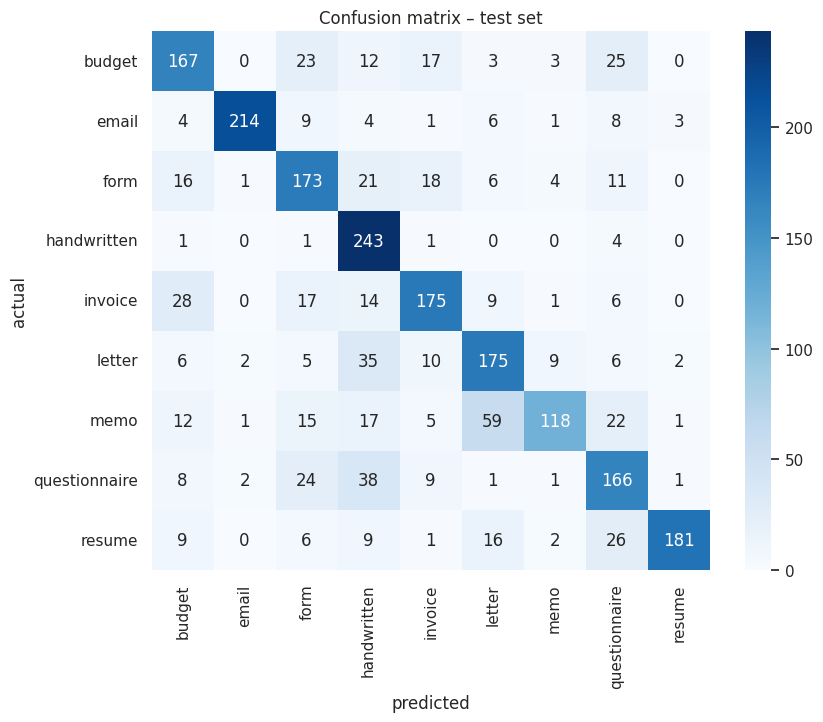

In [14]:
cm = np.array(metrics["confusion_matrix"])
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title("Confusion matrix – test set")
plt.show()

In [15]:
# Most frequent confusions (off-diagonal cells)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j]]
pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:8], columns=["actual", "predicted", "count"])

,actual,predicted,count
0,memo,letter,59
1,questionnaire,handwritten,38
2,letter,handwritten,35
3,invoice,budget,28
4,resume,questionnaire,26
5,budget,questionnaire,25
6,questionnaire,form,24
7,budget,form,23


### 6.2 API test set (used in production)

In [16]:
app_metrics = M.evaluate(model, x_app, y_app)
pd.DataFrame({"RVL-CDIP test sample": {k: metrics[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "n_samples")},
              "API test set": {k: app_metrics[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "n_samples")}}).round(3)

,RVL-CDIP test sample,API test set
accuracy,0.716,0.736
precision_macro,0.742,0.753
recall_macro,0.716,0.736
f1_macro,0.716,0.736
n_samples,2250.000,360.000


### Interpretation of the results
See the cell below – it is generated from the actual numbers.

In [17]:
rep = metrics["classification_report"]
f1s = {c: rep[c]["f1-score"] for c in CLASS_NAMES}
best, worst = max(f1s, key=f1s.get), min(f1s, key=f1s.get)
print(f"Overall: {metrics['accuracy']:.1%} accuracy on {metrics['n_samples']} unseen documents "
      f"(random guessing = {1/len(CLASS_NAMES):.1%}).")
print(f"Easiest type: {best} (F1 {f1s[best]:.2f}); hardest type: {worst} (F1 {f1s[worst]:.2f}).")
print("Macro precision ≈ recall means errors are spread evenly rather than one class absorbing predictions.")

Overall: 71.6% accuracy on 2250 unseen documents (random guessing = 11.1%).
Easiest type: email (F1 0.91); hardest type: memo (F1 0.61).
Macro precision ≈ recall means errors are spread evenly rather than one class absorbing predictions.


**What this means for a lender.** Because the classes are balanced, macro-averaged precision, recall and
F1 weigh every document type equally. Precision answers *"when the model says invoice, how often is it
really an invoice?"*; recall answers *"of all invoices, how many did it find?"*.

* **Reliable:** emails (F1 0.91) and resumes (0.83) have distinctive layouts, and when the model says
  "resume" or "email" it is right 96–97% of the time.
* **Most common confusion: memo → letter (59 of 250 memos).** Both are a block of typed paragraphs; the memo
  header is too small to read at 224×224. Memos therefore have high precision (0.85) but low recall (0.47).
* **Handwritten absorbs messy pages:** it finds 97% of handwritten notes, but scanned questionnaires and
  letters with handwriting on them are also predicted as handwritten (precision 0.62).
* **Grid documents** (budget / invoice / form / questionnaire) are confused with each other, as the ink-density
  analysis predicted.

In production, low-confidence predictions should be routed to a human reviewer rather than processed
automatically, and the most confused pairs are where uploaded data and retraining help most.

## 7. Prediction functions

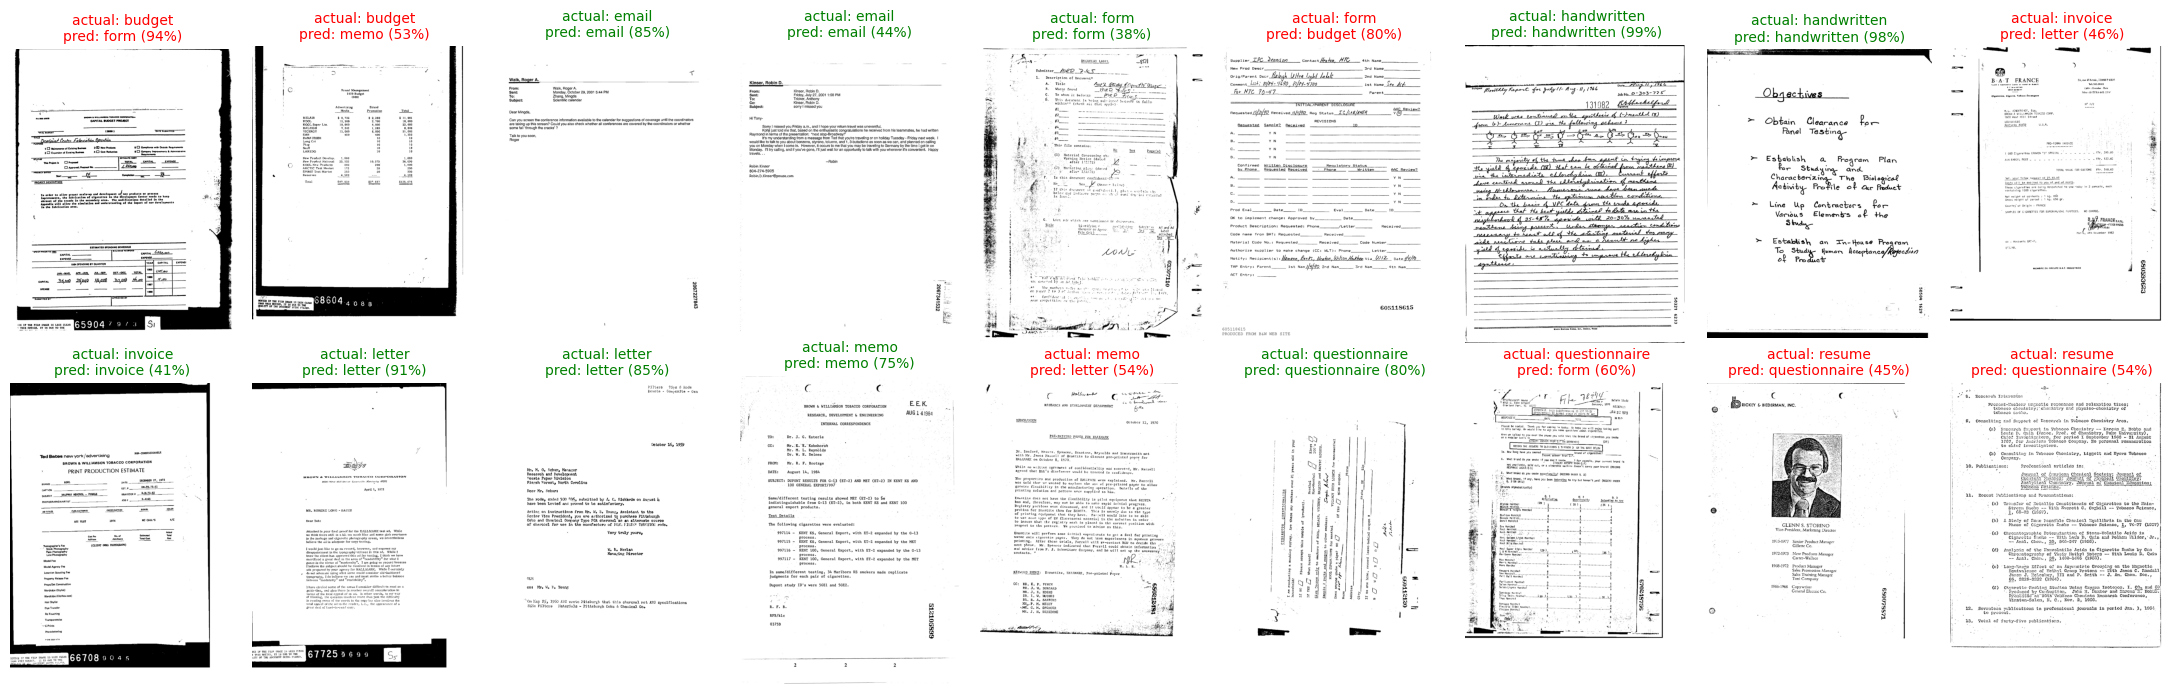

In [18]:
from src.prediction import Predictor

def predict_document(path, model=model):
    """Preprocess one image file and return (class, confidence, all probabilities)."""
    x = preprocessing.load_image(path)[None]
    probs = model(x, training=False).numpy()[0]
    return CLASS_NAMES[int(probs.argmax())], float(probs.max()), dict(zip(CLASS_NAMES, probs.round(3)))

samples = sorted(SAMPLES_DIR.glob("*.png"))
fig, axes = plt.subplots(2, 9, figsize=(22, 7))
for ax, f in zip(axes.flat, samples):
    label, conf, _ = predict_document(f)
    actual = f.name.split("_")[0]
    ax.imshow(plt.imread(f), cmap="gray"); ax.axis("off")
    ax.set_title(f"actual: {actual}\npred: {label} ({conf:.0%})", color="green" if label == actual else "red", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Save and register the model (version 1)

In [19]:
version = registry.next_version()
filename = f"doc_classifier_v{version}.h5"
M.save_model(model, MODELS_DIR / filename)
M.save_json(app_metrics, MODELS_DIR / "metrics.json")              # same test set the API evaluates on
M.save_json(metrics, MODELS_DIR / "metrics_rvl_test.json")
if ON_KAGGLE:
    (MODELS_DIR / "dataset_stats.json").write_text(json.dumps(stats))  # dashboard visualisations
M.save_json(history, MODELS_DIR / "history.json")
registry.record({
    "version": version, "file": filename, "kind": "initial", "status": "promoted",
    "created_at": registry.now_iso(), "train_samples": int(len(x_train)),
    "training_seconds": round(train_seconds, 1),
    "metrics": {k: app_metrics[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro")},
}, promote=True)
print("saved", MODELS_DIR / filename, f"{(MODELS_DIR / filename).stat().st_size/1e6:.1f} MB")

saved /kaggle/working/models/doc_classifier_v1.h5 25.0 MB


In [20]:
# Sanity check: the saved .h5 file reloads and the API's Predictor gives the same answer
p = Predictor()
f = samples[0]
print("notebook model:", predict_document(f)[:2])
print("reloaded model:", (lambda r: (r["predicted_class"], round(r["confidence"], 4)))(p.predict(f)), "version", p.version)

notebook model: ('form', 0.9366915822029114)
reloaded model: ('form', 0.9367) version 1
